# A5-Q3: GRU

In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pylab as plt
from tqdm import tqdm
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
print(device)


cuda


## Read in the data

The code below creates a dataset from an excerpt from Albert Einstein's _Relativity: The Special and the General Theory_ (1916).
  
Each list element represents a sequence of characters. There are 3 ways to represent a character:
1. `c`: As a character, eg. `'b'`
2. `i`: As an index to a character set, eg. `2`
3. `v`: As a one-hot vector, eg. `[0, 0, 1, 0, ...]` (`a` is at index 1)

These utility functions convert sequences between the 3 different representations.
  - `seq_v2i`
  - `seq_v2c`
  - `seq_c2i`
  - `seq_c2v`
  - `seq_i2v`
  - `seq_i2c`

In [5]:
import re
class Relativity(torch.utils.data.Dataset):
    def __init__(self, seq_length=10, start=0, stop=-1):
        self.seq_length = seq_length

        orig_text = open('einstein_relativity_book.txt', encoding='utf-8').read().lower()


        # Keep only letters, dot, and space; turn everything else into space
        allowed = set('abcdefghijklmnopqrstuvwxyz. ')
        clean_chars = []
        for c in orig_text:
            if c in allowed:
                clean_chars.append(c)
            else:
                clean_chars.append(' ')

        blah = ''.join(clean_chars)

        # collapse multiple spaces
        blah = re.sub(' +', ' ', blah)

        self.text = blah[start:stop]

        # build the final character set
        chars = sorted(list(set(self.text)))
        # ensure space is first character
        chars = [' '] + [c for c in chars if c != ' ']

        self.vocab_size = len(chars)
        print('Character set: "' + ''.join(chars) + '" (first char is a space)')

        self.char_indices = {c: i for i, c in enumerate(chars)}
        self.indices_char = {i: c for i, c in enumerate(chars)}
        self.idx = [self.char_indices[c] for c in self.text]

        print('There are ' + str(self.vocab_size) + ' characters in our character set')

    def __len__(self):
        return len(self.text) - 1 - self.seq_length
    
    def __getitem__(self, k):
        x = self.idx[k:k+self.seq_length]
        t = self.idx[k+1:k+1+self.seq_length]
        return self.seq_i2v(x), torch.tensor(t, dtype=torch.long)
      
    def seq_i2v(self, i):
        '''
        v = oos.seq_i2v(i)
        converts a sequence of indices to a sequence of 1-hot vectors
        i  (T,) tensor
        v  (T,28) tensor
        '''
        x = torch.zeros((len(i), self.vocab_size))
        for k,ii in enumerate(i):
            x[k,ii] = 1.
        return x
    
    def seq_v2i(self, v):
        '''
        i = oos.seq_v2i(v)
        converts a sequence of 1-hot vectors to a sequence of indices
        v  (T,28) tensor
        i  (T,) tensor
        '''
        return torch.tensor([torch.argmax(vv).item() for vv in v])
    
    def seq_i2c(self, i):
        '''
        c = oos.seq_i2c(i)
        converts a sequence of indices to a string
        i  (T,) tensor
        c  string
        '''
        return ''.join(self.indices_char[ii.item()] for ii in i)
    
    def seq_v2c(self, v):
        '''
        c = oos.seq_v2c(v)
        converts a sequence of 1-hot vectors to a string
        v  (T,28) tensor
        c  string
        '''
        i = self.seq_v2i(v)
        return self.seq_i2c(i)
    
    def seq_c2i(self, c):
        '''
        i = oos.seq_c2i(c)
        converts a string to a sequence of indices
        c  string
        i  (T,) tensor
        '''
        return torch.tensor([self.char_indices[cc] for cc in c])
    
    def seq_c2v(self, c):
        '''
        v = oos.seq_c2v(c)
        converts a string to a sequence of 1-hot vectors
        c  string
        v  (T,28) tensor
        '''
        i = self.seq_c2i(c)
        return self.seq_i2v(i)

In [6]:
oos = Relativity(start=10300, stop=25596, seq_length=50)

Character set: " .abcdefghijklmnopqrstuvwxyz" (first char is a space)
There are 28 characters in our character set


In [7]:
oos.char_indices

{' ': 0,
 '.': 1,
 'a': 2,
 'b': 3,
 'c': 4,
 'd': 5,
 'e': 6,
 'f': 7,
 'g': 8,
 'h': 9,
 'i': 10,
 'j': 11,
 'k': 12,
 'l': 13,
 'm': 14,
 'n': 15,
 'o': 16,
 'p': 17,
 'q': 18,
 'r': 19,
 's': 20,
 't': 21,
 'u': 22,
 'v': 23,
 'w': 24,
 'x': 25,
 'y': 26,
 'z': 27}

In [8]:
# Number of training sequences
len(oos)

15245

In [9]:
oos.text

' interpretation of distance which has been indicated we are also in a position to establish the distance between two points on a rigid body by means of measurements. for this purpose we require a distance rod s which is to be used once and for all and which we employ as a standard measure. if now a and b are two points on a rigid body we can construct the line joining them according to the rules of geometry then starting from a we can mark off the distance s time after time until we reach b . the number of these operations required is the numerical measure of the distance ab . this is the basis of all measurement of length. here we have assumed that there is nothing left over i.e. that the measurement gives a whole number. this difficulty is got over by the use of divided measuring rods the introduction of which does not demand any fundamentally new method. every description of the scene of an event or of the position of an object in space is based on the specification of the point on

In [10]:
# Total number of characters
len(oos.text)

15296

In [11]:
# Get a sequence, both input and target
x, t = oos.__getitem__(0)

In [12]:
# A sequence of 50 one-hot vectors
x.shape

torch.Size([50, 28])

In [13]:
# Indecies of 50 targets
t

tensor([10, 15, 21,  6, 19, 17, 19,  6, 21,  2, 21, 10, 16, 15,  0, 16,  7,  0,
         5, 10, 20, 21,  2, 15,  4,  6,  0, 24,  9, 10,  4,  9,  0,  9,  2, 20,
         0,  3,  6,  6, 15,  0, 10, 15,  5, 10,  4,  2, 21,  6])

In [14]:
# Convert the input sequence to a string
oos.seq_v2c(x)

' interpretation of distance which has been indicat'

In [15]:
print('Here is how you can view one of the sample sequences:')
print(f'         Sample input: "{oos.seq_v2c(x)}"')
print(f'Corresponding targets: "{oos.seq_i2c(t)}"')

Here is how you can view one of the sample sequences:
         Sample input: " interpretation of distance which has been indicat"
Corresponding targets: "interpretation of distance which has been indicate"


In [16]:
# We'll use this DataLoader for minibatch SGD
dl = torch.utils.data.DataLoader(oos, batch_size=128, shuffle=True)

In [17]:
# Let's get a batch just to see what it looks like.
xb, tb = next(iter(dl))
print(xb.shape)

torch.Size([128, 50, 28])


In [18]:
k = 0
print(f'Taking sequence {k} from the batch:')
print(f'         Sample input: "{oos.seq_v2c(xb[k])}"')
print(f'Corresponding targets:  "{oos.seq_i2c(tb[k])}"')

Taking sequence 0 from the batch:
         Sample input: ". that the measurement gives a whole number. this "
Corresponding targets:  " that the measurement gives a whole number. this d"


# Q3 (a) Complete `GRU`

In [19]:
class GRU(nn.Module):
    '''
     net = GRU(in_dim, hidden_dim, out_dim, outfcn=nn.LogSoftmax(dim=-1))

     Create a (standard) GRU network.

     Inputs:
      in_dim      dimension of input
      hidden_dim  dimension of hidden layers
      out_dim     dimension of output
      outfcn      activation function for output
                  (default: nn.LogSoftmax(dim=-1))

     Usage:
     > net = GRU(28, 300, 28, outfcn=nn.Tanh())
     > x = torch.randn((3, 10, 28))  # batch of 3 sequences of length 10
     > y = net(x)
     Returns y with shape (3, 10, 28)
     
     > y = net.step(x[:,0,:].unsqueeze(1))
     Returns y with shape (3, 1, 28)
    '''
    def __init__(self, in_dim, hidden_dim, out_dim, outfcn=nn.LogSoftmax(dim=-1)):
        super().__init__()
        self.in_dim = in_dim          # input dimension
        self.hidden_dim = hidden_dim  # hidden dimension
        self.out_dim = out_dim        # output dimension

        self.h = None
        

        #===== YOUR CODE HERE =====
        self.Uz = nn.Linear(in_dim, hidden_dim, bias=True)
        self.Wz = nn.Linear(hidden_dim, hidden_dim, bias=False)

        self.Ur = nn.Linear(in_dim, hidden_dim, bias=True)
        self.Wr = nn.Linear(hidden_dim, hidden_dim, bias=False)

        self.Uh = nn.Linear(in_dim, hidden_dim, bias=True)
        self.Wh = nn.Linear(hidden_dim, hidden_dim, bias=False)

        self.V  = nn.Linear(hidden_dim, out_dim, bias=True)
        self.outfcn = outfcn
        #==========================


        self.losses = []
        self.to(device)
    
    def reset(self):
        self.h = None

    def step(self, x):
        '''
        y = net.step(x)

        Performs one time step of an entire batch, using the input x and the
        saved hidden state (net.h) to generate the output y.
        
        Input:
         x  (batch_size, 1, in_dim) tensor

        Output:
         y  (batch_size, 1, out_dim) tensor
        '''
        _, T, _ = x.shape
        assert T == 1, 'GRU.step: x must have shape (batch_size, 1, in_dim)'
        if self.h is None:
            # store hidden state as 2D tensor: (batch, hidden_dim)
            self.h = torch.zeros((x.shape[0], self.hidden_dim), device=device)


        #===== YOUR CODE HERE =====
        xt = x[:, 0, :]            # (batch, in_dim)

        # ---- GRU FORMULAS ----
        z = torch.sigmoid(self.Uz(xt) + self.Wz(self.h))
        r = torch.sigmoid(self.Ur(xt) + self.Wr(self.h))

        h_tilde = torch.tanh(self.Uh(xt) + self.Wh(r * self.h))

        self.h = (1 - z) * self.h + z * h_tilde

        # output
        y_t = self.outfcn(self.V(self.h))

        return y_t.unsqueeze(1)
        #==========================

    def forward(self, x_batch):
        '''
        y = net.forward(x_batch) or y = net(x_batch)

        Performs a forward pass of an entire batch of sequences, using the input x_batch to
        generate the output y.
        The hidden state, h, is carried forward through timesteps but not returned.

        Input:
         x_batch  (batch_size, T, in_dim) tensor

        Output:
         y        (batch_size, T, out_dim) tensor
        '''
        # The input x_batch is a batch of sequences of one-hot vectors.
        samples, T, in_dim = x_batch.shape
        assert in_dim == self.in_dim, 'GRU.forward: x_batch must have shape (batch_size, T, in_dim)'

        x_batch = x_batch.to(device)   # just in case you have a GPU
        self.reset()
        

        #===== YOUR CODE HERE =====
        y = []
        for t in range(T):
            y_t = self.step(x_batch[:, t:t+1, :])
            y.append(y_t)
        y = torch.cat(y, dim=1)
        #==========================


        return y

    def predict(self, x, n=10):
        '''
        y = net.predict(x, n=10)

        Given a sequence of one-hot vectors x, predict the next n
        outputs.

        Inputs:
         x  (1, T, in_dim) tensor, where T is the length of the sequence
         n  int, the number of outputs to predict

        Outputs:
         y  (1, n, out_dim) tensor of probability vectors
        '''
        with torch.no_grad():
            assert x.shape[0] == 1, 'predict: x must have shape (1, T, in_dim)'
            assert x.shape[2] == self.in_dim, 'predict: x must have shape (1, T, in_dim)'
            # initialize output to hold predicted probability vectors
            output = torch.zeros((1, n, self.out_dim), device=device)
            self.reset()  # Reset all hidden states


        #===== YOUR CODE HERE =====
        with torch.no_grad():
            T = x.shape[1]
            self.reset()

            # run full prompt
            for t in range(T):
                _ = self.step(x[:, t:t+1, :])

            # now autoregressive prediction
            last = x[:, -1:, :]
            for k in range(n):
                y_t = self.step(last)
                output[:, k:k+1, :] = y_t

                # convert predicted distribution → one-hot input
                idx = torch.argmax(y_t, dim=2)
                onehot = torch.zeros(1, 1, self.in_dim, device=device)
                onehot[0,0,idx] = 1
                last = onehot
        #===== YOUR CODE HERE =====
                
        #=====================


        return output

    def bptt(self, dl, epochs=10, lr=0.001):
        '''
        net.bptt(dl, epochs=10, lr=0.001)
        Perform backprop-through-time (BPTT) to learn from the sequences in the dataset.
         dl      Dataloader object (see above)
         epochs  How many epochs to train for
         lr      Learning rate
        '''
        loss_fcn = nn.NLLLoss()
        optim = torch.optim.Adam(self.parameters(), lr=lr)
        for epoch in tqdm(range(epochs)):
            total_loss = 0.
            for x,t in (dl):
                x = x.to(device) # i changed here for training on cuda
                t = t.to(device)
                y = self(x)
                # Loss is summed over time steps
                loss = torch.tensor(0., device=device, requires_grad=True)
                for k in range(t.shape[1]):
                    ys = y[:,k,:].squeeze()
                    ts = t[:,k]
                    loss = loss + loss_fcn(ys, ts)
                optim.zero_grad()
                loss.backward()
                optim.step()
                total_loss += loss.detach().cpu().item() * len(t)
            self.losses.append(total_loss/len(dl.dataset))
        plt.plot(self.losses)

# Q3 (b) Train it

In [20]:
net = GRU(oos.vocab_size, 200, oos.vocab_size).to(device)

100%|██████████| 10/10 [01:06<00:00,  6.62s/it]


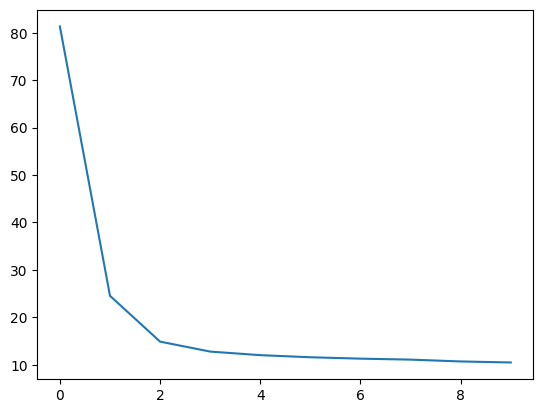

In [21]:
net.bptt(dl, epochs=10, lr=0.01) # you might have to some hyperparameter tuning here
torch.cuda.empty_cache()


In [22]:
# You can save and re-load your model if you choose.
# Save
torch.save(net.cpu(), 'relativity.pt')
# Load
net = torch.load('relativity.pt', map_location=device)
net = net.to(device)


C:\Users\Ambrose\AppData\Local\Temp\ipykernel_18020\496348533.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net = torch.load('relativity.pt', map_location=device)


# Q4 (c) Next-Letter Prediction Accuracy

In [23]:
#===== YOUR CODE HERE =====
# Get last output for each sequence in the dataset

# Check if the last output matches the target

# Report what fraction of the sequences in the data yielded the correct next letter

#==========================

correct = 0
total = 0

net.eval()   # evaluation mode

with torch.no_grad():
    for x, t in dl:                          # x: (batch, T, 28), t: (batch, T)
        x = x.to(device)
        t = t.to(device)

        y = net(x)                           # (batch, T, 28)
        last_output = y[:, -1, :]            # predicted distribution at final time step
        last_target = t[:, -1]               # true target index at final step

        pred_idx = torch.argmax(last_output, dim=1)

        correct += (pred_idx == last_target).sum().item()
        total += last_target.numel()

accuracy = correct / total
print(f"Next-letter prediction accuracy: {accuracy * 100:.2f}%")


Next-letter prediction accuracy: 99.54%


# Q4 (d) Predict the next 250 characters

In [25]:
# Choose a sequence randomly
v,t = oos.__getitem__(np.random.randint(len(oos)))

# Or enter your own prompt (don't be rude)
# v = oos.seq_i2v([oos.char_indices[cc] for cc in 'relativity principle'])

# Use v.unsqueeze(0) to make it a batch with one sequence

# Predict the next 160 characters


#===== YOUR CODE HERE =====
x = v.unsqueeze(0).to(device)

y_pred = net.predict(x, n=250)

pred_indices = torch.argmax(y_pred, dim=2).squeeze(0)
pred_text = oos.seq_i2c(pred_indices)


#==========================


print(f'{oos.seq_v2c(v.squeeze())}\033[31m{pred_text[:100]}\033[0m')
print(f'\033[31m{pred_text[100:]}\033[0m')

 k provided that the latter is executing a uniformer the earth cannot be at rest relative to the hypothetical system k throughout the whole year. howe
ver the most careful observations have never revealed such anisotropic properties in terrestrial physical space i.e. a physical non equivalence of dif


In [26]:
#some more test use random sequences from txt file

for i in range(5):
    v, t = oos.__getitem__(np.random.randint(len(oos)))
    x = v.unsqueeze(0).to(device)

    y_pred = net.predict(x, n=250)
    pred_indices = torch.argmax(y_pred, dim=2).squeeze()
    pred_text = oos.seq_i2c(pred_indices)

    print(f"\n=== Random Prompt #{i+1} ===")
    print(oos.seq_v2c(v.squeeze()) + "\033[31m" + pred_text[:150] + "\033[0m")



=== Random Prompt #1 ===
pplies us with the actual motions of the heavenly overvations have never revealed such anisotropic properties in terrestrial physical space i.e. a physical non equivalence of different directions. thi

=== Random Prompt #2 ===
phenomena and yet should be invalid for another isa condition of uniform motion of translation. relative to k the mechanical laws of galilei newton hold good exactly as they do with respect to k . we 

=== Random Prompt #3 ===
iling here we shall have to deal in detail later. vatuen event will be determined for the main part by the specification of the lengths of the three perpendiculars can be determined by a series of man

=== Random Prompt #4 ===
to k . in accordance with the discussion containeditutround the number of these operations required is the numerical measure of the distance ab . this is the basis of all measurement of length. here w

=== Random Prompt #5 ===
ndirect means. if the results of physics and astroody to which suc